# Park et al. (2023), Figure 3: simulation families

Section 3.1 defines three synthetic settings: (A) AR mean change, (B-i) AR second-order change, and (C) MA second-order change. The six panels use n=1024, p=50, and a breakpoint at 512. The plots below use **new seeded draws**, not the authors' original sample traces. The unmodified signed data are plotted to reproduce the *types* of time series in Figure 3.

**Caution:** The current positive-mean-normalized `mean_cusum_curves` should not be applied to these signed raw values. Models B and C require second-order monitoring. No detector success is claimed here.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "simulation" / "park_structural_models.py").is_file():
    raise FileNotFoundError("Start Jupyter from the repository root or notebooks/.")
sys.path.insert(0, str(ROOT))
from src.simulation.park_structural_models import simulate_park_model

## Model A: Gaussian Innovation Distribution

Park et al. (2023) specify the innovation term:

$$
\epsilon_t^{(d)} \sim N(0,4)
$$

Here:
- The mean is 0.
- The variance is 4.
- The standard deviation is 2.
- Each channel receives a sequence of Gaussian innovations.

The following experiment examines the innovation distribution before it is incorporated into the autoregressive model.

Innovation matrix: (1024, 50)
Sample mean: 0.012356536052893276
Sample variance: 4.016117270199342
Theoretical mean: 0
Theoretical variance: 4


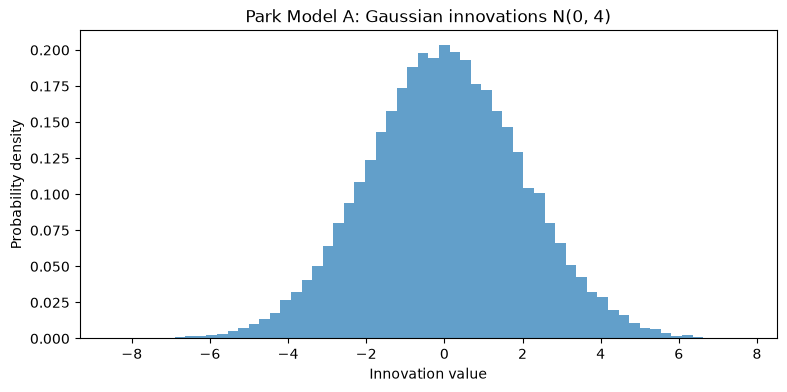

In [5]:

# Model A: Gaussian innovations
# epsilon_t^(d) ~ N(0, 4)

rng = np.random.default_rng(2023)

eps = rng.normal(
    loc=0.0,
    scale=2.0,
    size=(1024, 50),
)

print("Innovation matrix:", eps.shape)
print("Sample mean:", eps.mean())
print("Sample variance:", eps.var())
print("Theoretical mean: 0")
print("Theoretical variance: 4")

plt.figure(figsize=(9, 4))
plt.hist(
    eps.flatten(),
    bins=60,
    density=True,
    alpha=0.7,
)

plt.xlabel("Innovation value")
plt.ylabel("Probability density")
plt.title("Park Model A: Gaussian innovations N(0, 4)")
plt.show()

## Figure 3-style six-panel comparison
The no-change column uses an independent no-change simulation; the changed column plots one affected channel. In the source figure the displayed channels are randomly selected. Parameter choices below follow the stated model families.

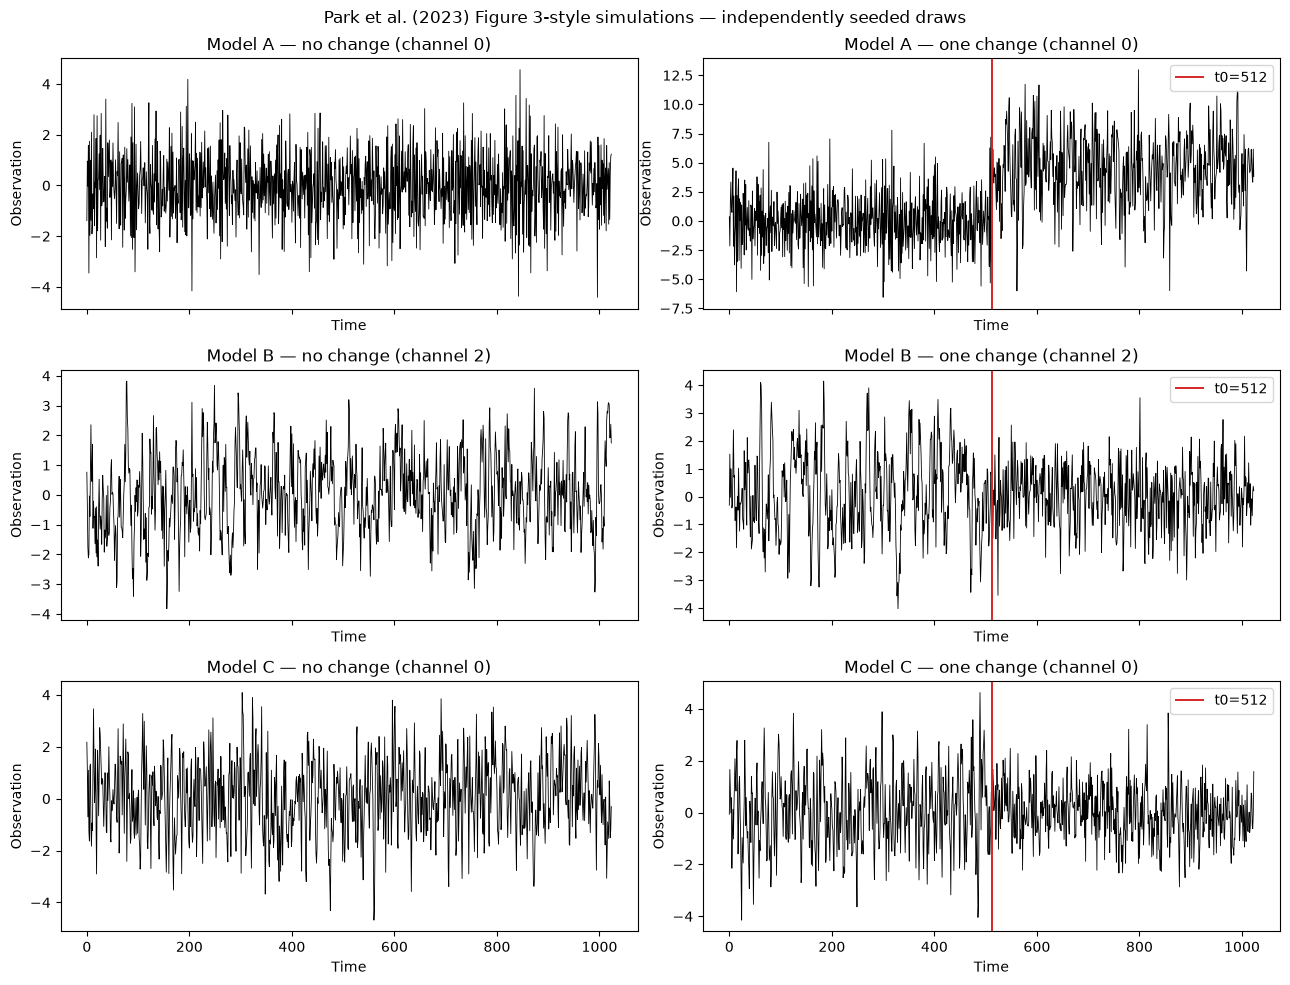

In [2]:
n, p, breakpoint, rho = 1024, 50, 512, 0.5
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)
runs = {}
for row, model in enumerate(("A", "B", "C")):
    no_change = simulate_park_model(model, n=n, channels=p, change_at=None, rho=rho, seed=2023 + row)
    changed = simulate_park_model(model, n=n, channels=p, change_at=breakpoint, rho=rho, seed=3023 + row)
    runs[model] = (no_change, changed)
    channel = changed["affected_channels"][0]
    for col, (dataset, index) in enumerate(((no_change, channel), (changed, channel))):
        ax = axes[row, col]
        ax.plot(np.arange(n), dataset["values"][:, index], lw=0.6, color="black")
        if col == 1:
            ax.axvline(breakpoint, color="tab:red", lw=1.4, label="t0=512")
            ax.legend(loc="upper right")
        ax.set_title(f"Model {model} — {'no change' if col == 0 else 'one change'} (channel {index})")
        ax.set_ylabel("Observation")
        ax.set_xlabel("Time")
fig.suptitle("Park et al. (2023) Figure 3-style simulations — independently seeded draws")
fig.tight_layout()
plt.show()

## Reproducibility and statistical properties
Confirm shapes and expected channel-selection size. For Model A, affected channels should exhibit an increased post-change mean; B and C primarily change temporal dependence.

In [3]:
for model, (null, changed) in runs.items():
    assert null["values"].shape == changed["values"].shape == (1024, 50)
    assert len(null["affected_channels"]) == 0
    assert len(changed["affected_channels"]) == int(np.floor(rho*p))
    idx = np.asarray(changed["affected_channels"], dtype=int)
    before = changed["values"][:breakpoint, idx]
    after = changed["values"][breakpoint:, idx]
    print(model, "affected:", len(idx), "mean before:", round(float(before.mean()), 3),
          "mean after:", round(float(after.mean()), 3))
    assert np.isfinite(changed["values"]).all()

A affected: 25 mean before: -0.017 mean after: 5.736
B affected: 25 mean before: 0.008 mean after: 0.005
C affected: 25 mean before: 0.007 mean after: 0.009


## Beyond the illustration
The paper also tests `n=512`, change points 100/256, and `n=1024` with change point 100/512. Sparsity levels include `rho=0.7,0.5,0.3,0.2,0.1`. Model B(ii), with correlated innovations and changed cross-dependence, is **not implemented** by this generator. The plotted series cannot reproduce the original precise noise trajectory without its seed. Future work: replicate second-order detector evaluation over repeated draws and document success criteria.

In [4]:
alternative = simulate_park_model("B", n=512, channels=50, change_at=256,
                                  rho=0.2, seed=1201)
assert alternative["values"].shape == (512, 50)
assert len(alternative["affected_channels"]) == 10
print("Alternative published simulation dimensions and rho: validated")

Alternative published simulation dimensions and rho: validated
